## Polynomial & Interaction Terms

### 1. Dependencies

In [1]:
from prep import *
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.base import BaseEstimator, TransformerMixin

X_train, X_test, y_train, y_test, meta = load_model_data()
print(f"{X_train.shape[1]} lagged features, {len(X_train)} training quarters")

train 1992-03-31 to 2014-12-31  (92, 27)
test  2015-03-31 to 2025-12-31  (44, 27)
27 lagged features, 92 training quarters


### 2. Baseline Model

In [2]:
linear = make_pipeline(*preprocess(scale=True), LinearRegression()).fit(X_train, y_train)
score(linear, X_train, X_test, y_train, y_test)

,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.161,0.102,0.927,0.761,92.0
model - test,0.387,0.179,-1.307,0.591,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.132,0.108,0.607,0.583,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


In [3]:
record("Linear (no extra terms)", linear, X_train, X_test, y_train, y_test,
       notes="OLS on lagged features, baseline for notebook 1")

recorded 'Linear (no extra terms)' -> /workspaces/DX799-O1/model_data/results


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.161,0.102,0.927,0.761,92.0
model - test,0.387,0.179,-1.307,0.591,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.132,0.108,0.607,0.583,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


### > **Note:** Below are all the possible interaction terms available.

In [4]:
p = X_train.shape[1]
rows = []
for degree in [1, 2, 3]:
    for inter_only in [False, True]:
        n = PolynomialFeatures(degree, interaction_only=inter_only, include_bias=False).fit(X_train.fillna(0)).n_output_features_
        rows.append({"degree": degree, "interaction_only": inter_only, "terms": n,
                     "terms per training quarter": round(n / len(X_train), 1)})
pd.DataFrame(rows)

,degree,interaction_only,terms,terms per training quarter
0,1,False,27,0.3
1,1,True,27,0.3
2,2,False,405,4.4
3,2,True,378,4.1
4,3,False,4059,44.1
5,3,True,3303,35.9


> **Add. Note:** Degree 3 is skipped since there is no economic reason for it and it adds unnecessary model complexity.

### 3. All Poly Terms + Ridge (for regularization) | A

In [5]:
poly_pipe = make_pipeline(*preprocess(scale=False),
                          PolynomialFeatures(include_bias=False),
                          StandardScaler(),
                          Ridge())
poly_grid = {"polynomialfeatures__degree": [1, 2],
             "polynomialfeatures__interaction_only": [False, True],
             "ridge__alpha": np.logspace(-2, 5, 30)}
poly_search = tune(poly_pipe, poly_grid, X_train, y_train)
poly_best = poly_search.best_estimator_

best params: {'polynomialfeatures__degree': 1, 'polynomialfeatures__interaction_only': False, 'ridge__alpha': np.float64(23.95026619987486)}
best CV root_mean_squared_error: 0.3841


#### 1. Penalty and Degree Effect

<Axes: title={'center': 'Tuning: alpha by degree'}, xlabel='alpha', ylabel='root mean squared error'>

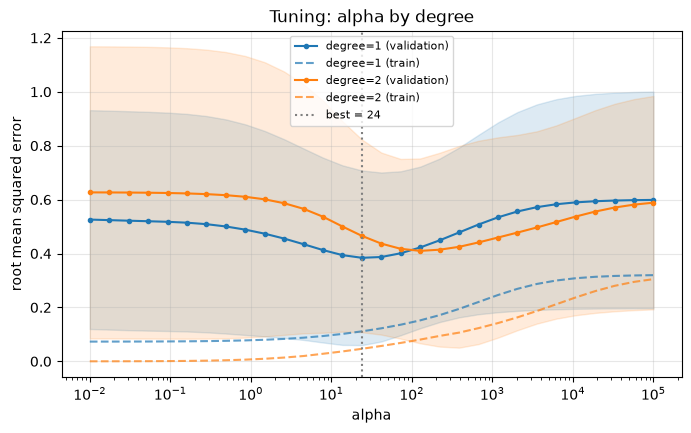

In [6]:
plot_tuning(poly_search, "ridge__alpha", by="polynomialfeatures__degree")

<Axes: title={'center': 'CV root mean squared error'}, xlabel='interaction_only', ylabel='degree'>

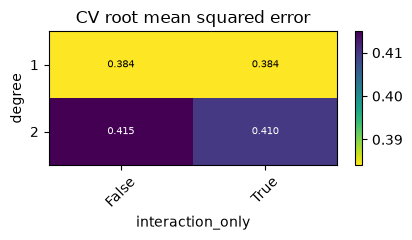

In [7]:
# best CV RMSE for each degree / interaction_only combination (each at its own best alpha)
plot_tuning_heatmap(poly_search, "polynomialfeatures__interaction_only", "polynomialfeatures__degree", fmt=".3f")

In [8]:
tuning_table(poly_search, top=20)

,polynomialfeatures__degree,polynomialfeatures__interaction_only,ridge__alpha,cv_root_mean_squared_error,cv_root_mean_squared_error_sd,train_root_mean_squared_error,gap (cv - train),rank
0,1,False,23.950266,0.384120,0.323934,0.111203,0.272917,1
1,1,True,23.950266,0.384120,0.323934,0.111203,0.272917,1
2,1,True,41.753189,0.387031,0.313472,0.122531,0.264500,3
3,1,False,41.753189,0.387031,0.313472,0.122531,0.264500,3
4,1,False,13.738238,0.394014,0.333105,0.101650,0.292364,5
5,1,True,13.738238,0.394014,0.333105,0.101650,0.292364,5
6,1,True,72.789538,0.400995,0.304120,0.135928,0.265067,7
7,1,False,72.789538,0.400995,0.304120,0.135928,0.265067,7
8,2,True,126.896100,0.409783,0.342885,0.080677,0.329105,9
9,1,False,7.880463,0.412730,0.342901,0.093827,0.318903,10


#### 2. Accuracy

In [9]:
score(poly_best, X_train, X_test, y_train, y_test)

,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.195,0.136,0.893,0.609,92.0
model - test,0.361,0.157,-1.014,0.636,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.122,0.102,0.665,0.667,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


<Axes: title={'center': 'Polynomial + Ridge: actual vs forecast'}, ylabel='co_other_cons'>

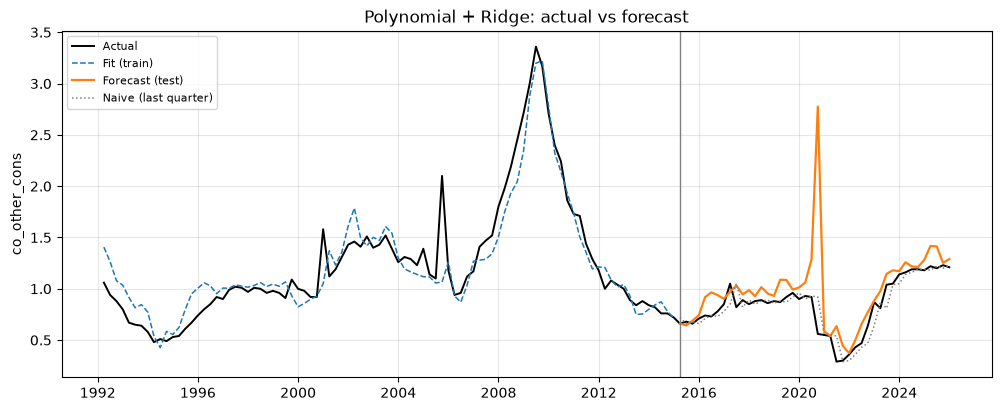

In [10]:
plot_forecast(poly_best, X_train, X_test, y_train, y_test, title="Polynomial + Ridge: actual vs forecast")

#### 3. Important Terms in the Model

In [11]:
w = feature_weights(poly_best, X_train)
print(f"{len(w)} terms; showing the largest")
w.head(20)

27 terms; showing the largest


,feature,weight,abs weight,used,variable
0,co_other_cons_L1,0.191306,0.191306,True,co_other_cons
1,emp_constr_L1,-0.068345,0.068345,True,emp_constr
2,dq_other_cons_L2,0.058871,0.058871,True,dq_other_cons
3,dq_other_cons_L1,0.058393,0.058393,True,dq_other_cons
4,co_credit_card_L2,0.057874,0.057874,True,co_credit_card
5,emp_constr_L2,-0.046794,0.046794,True,emp_constr
6,emp_info_L1,-0.038422,0.038422,True,emp_info
7,co_credit_card_L1,0.033271,0.033271,True,co_credit_card
8,credit_cons_total_L1,-0.029015,0.029015,True,credit_cons_total
9,house_cs10_L1,-0.026611,0.026611,True,house_cs10


<Axes: title={'center': 'Feature weights (coefficient)'}>

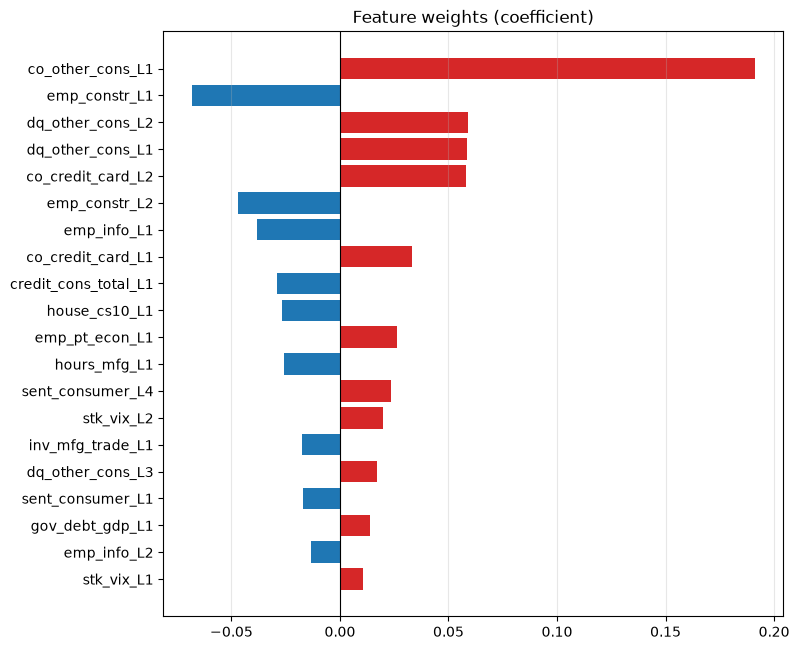

In [12]:
plot_feature_weights(poly_best, X_train, top=20)

In [13]:
# how much weight went to original features vs squares vs interactions
w["term type"] = np.where(w["feature"].str.contains(r"\^2"), "squared",
                  np.where(w["feature"].str.contains(" "), "interaction", "original (linear)"))
w.groupby("term type")["abs weight"].agg(["count", "sum"]).assign(share=lambda d: d["sum"] / d["sum"].sum()).round(3)

,count,sum,share
term type,,,
original (linear),27,0.811,1.0


#### 4. Overfitting

<Axes: title={'center': 'Permutation importance (big train, small test = likely overfit)'}, xlabel='drop in root_mean_squared_error when shuffled'>

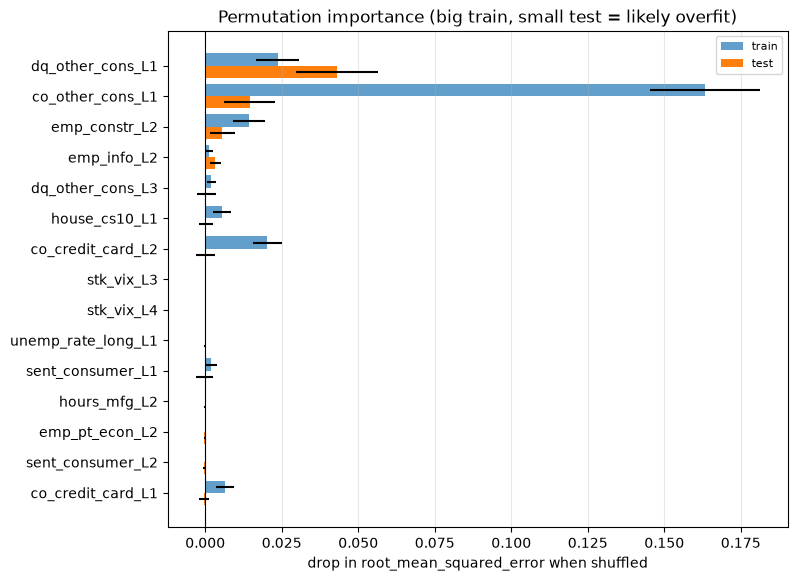

In [14]:
perm_poly = permutation_table(poly_best, X_train, y_train, X_test, y_test, n_repeats=20)
plot_permutation(perm_poly, top=15)

In [15]:
record("Poly + Ridge", poly_best, X_train, X_test, y_train, y_test, search=poly_search,
       notes="PolynomialFeatures -> StandardScaler -> Ridge")

recorded 'Poly + Ridge' -> /workspaces/DX799-O1/model_data/results


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.195,0.136,0.893,0.609,92.0
model - test,0.361,0.157,-1.014,0.636,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.122,0.102,0.665,0.667,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


### 4. Few Targeted/Selected Terms | B

In [16]:
class AddTerms(BaseEstimator, TransformerMixin):
    # Adds chosen interaction (a x b) and squared (a^2) columns. Pure arithmetic on each row,
    # nothing is learned from the data, so it cannot leak information between train and test.
    def __init__(self, pairs=(), squares=()):
        self.pairs, self.squares = pairs, squares
    def fit(self, X, y=None):
        self.feature_names_in_ = np.array(X.columns)
        return self
    def transform(self, X):
        X = X.copy()
        for a, b in self.pairs:
            X[f"{a} x {b}"] = X[a] * X[b]
        for a in self.squares:
            X[f"{a}^2"] = X[a] ** 2
        return X
    def get_feature_names_out(self, input_features=None):
        return np.array(list(self.feature_names_in_)
                        + [f"{a} x {b}" for a, b in self.pairs] + [f"{a}^2" for a in self.squares])

> **Note:** Here below I hand pick which pairs and squares go into the model

In [ ]:
# candidate terms with an economic story; anything not in X_train is skipped
''' # Run 2
PAIRS = [
    ("dq_other_cons_L1", "unemp_rate_long_L1"),
    ("dq_other_cons_L1", "house_cs10_L1"),
    ("emp_pt_econ", "unemp_rate_long_L1"),
    ("sent_consumer_L1", "unemp_rate_long_L1"),
]
SQUARES = ["stk_vix_L1", "sent_consumer_L1","gov_debt_gdp","co_credit_card_L1"]'''

# Run 1 More Simple
PAIRS = [
    ("dq_other_cons_L1", "unemp_rate_long_L1"),
    ("dq_other_cons_L1", "house_cs10_L1"),
    ("co_credit_card_L1", "unemp_rate_long_L1"),
    ("sent_consumer_L1", "unemp_rate_long_L1"),
]
SQUARES = ["stk_vix_L1", "sent_consumer_L1"]

have = set(X_train.columns)
PAIRS = [(a, b) for a, b in PAIRS if a in have and b in have]
SQUARES = [a for a in SQUARES if a in have]
print("pairs used:", PAIRS)
print("squares used:", SQUARES)

pairs used: [('dq_other_cons_L1', 'unemp_rate_long_L1'), ('dq_other_cons_L1', 'house_cs10_L1'), ('co_credit_card_L1', 'unemp_rate_long_L1'), ('sent_consumer_L1', 'unemp_rate_long_L1')]
squares used: ['stk_vix_L1', 'sent_consumer_L1']


> **Note:** Tuning - All combinations of terms are tested: No extra terms vs squares vs interactions vs both together. Along with CV to determine which work best.

In [49]:
term_options = {
    "none": dict(pairs=(), squares=()),
    "squares": dict(pairs=(), squares=tuple(SQUARES)),
    "interactions": dict(pairs=tuple(PAIRS), squares=()),
    "both": dict(pairs=tuple(PAIRS), squares=tuple(SQUARES)),
}
target_pipe = make_pipeline(AddTerms(), *preprocess(scale=True), Ridge())
target_grid = [{"addterms__pairs": [o["pairs"]], "addterms__squares": [o["squares"]],
                "ridge__alpha": np.logspace(-3, 4, 25)} for o in term_options.values()]
target_search = tune(target_pipe, target_grid, X_train, y_train)
target_best = target_search.best_estimator_

best params: {'addterms__pairs': (('dq_other_cons_L1', 'unemp_rate_long_L1'), ('dq_other_cons_L1', 'house_cs10_L1'), ('co_credit_card_L1', 'unemp_rate_long_L1'), ('sent_consumer_L1', 'unemp_rate_long_L1')), 'addterms__squares': (), 'ridge__alpha': np.float64(23.71373705661655)}
best CV root_mean_squared_error: 0.3531


In [50]:
# best CV score for each option (each at its own best alpha)
t = tuning_table(target_search)
label = {(str(o["pairs"]), str(o["squares"])): k for k, o in term_options.items()}
t["terms added"] = [label[(str(p), str(s))] for p, s in zip(t["addterms__pairs"], t["addterms__squares"])]
t.sort_values("rank").groupby("terms added", sort=False).first()[["ridge__alpha", "cv_root_mean_squared_error", "train_root_mean_squared_error"]]

,ridge__alpha,cv_root_mean_squared_error,train_root_mean_squared_error
terms added,,,
interactions,23.713737,0.353107,0.105934
both,23.713737,0.358119,0.105536
none,23.713737,0.384188,0.111017
squares,46.415888,0.389402,0.124639


#### 1. Accuracy

In [51]:
score(target_best, X_train, X_test, y_train, y_test)

,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.180,0.125,0.908,0.652,92.0
model - test,0.268,0.139,-0.109,0.614,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.099,0.081,0.779,0.667,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


#### 2. Weights

<Axes: title={'center': 'Targeted terms + Ridge: weights'}>

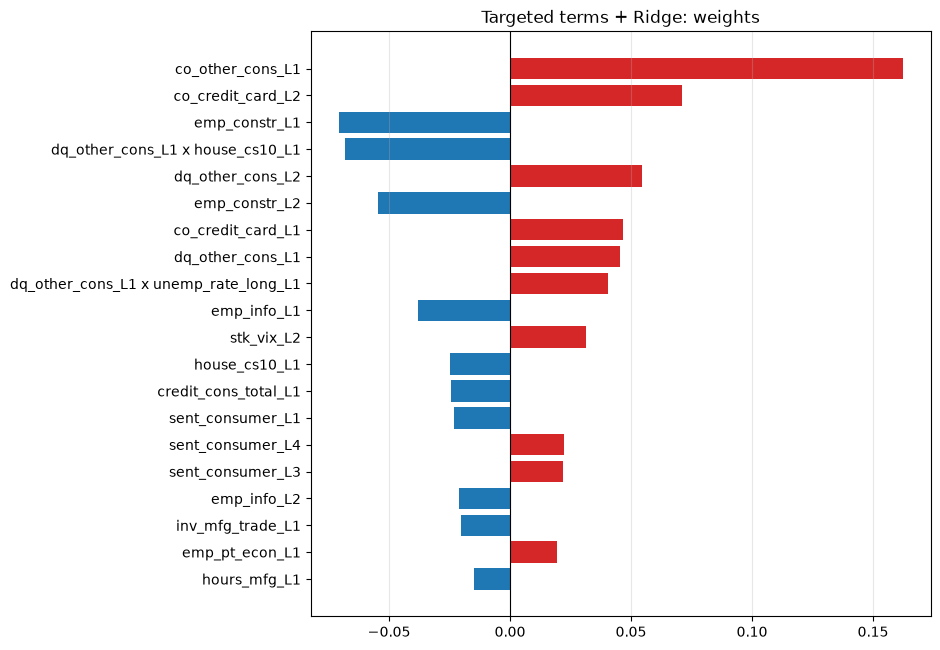

In [52]:
plot_feature_weights(target_best, X_train, top=20, title="Targeted terms + Ridge: weights")

,full-training weight,mean across folds,sd across folds,share of folds used,sign flips
feature,,,,,
dq_other_cons_L1 x house_cs10_L1,-0.068211,-0.023824,0.028760,1.0,False
dq_other_cons_L1 x unemp_rate_long_L1,0.040430,0.015183,0.017552,1.0,True
co_credit_card_L1 x unemp_rate_long_L1,0.004178,0.005798,0.005429,1.0,True
sent_consumer_L1 x unemp_rate_long_L1,-0.003631,0.004882,0.010248,1.0,True


<Axes: title={'center': 'Weight stability across time folds (dots = folds, bar = full training)'}>

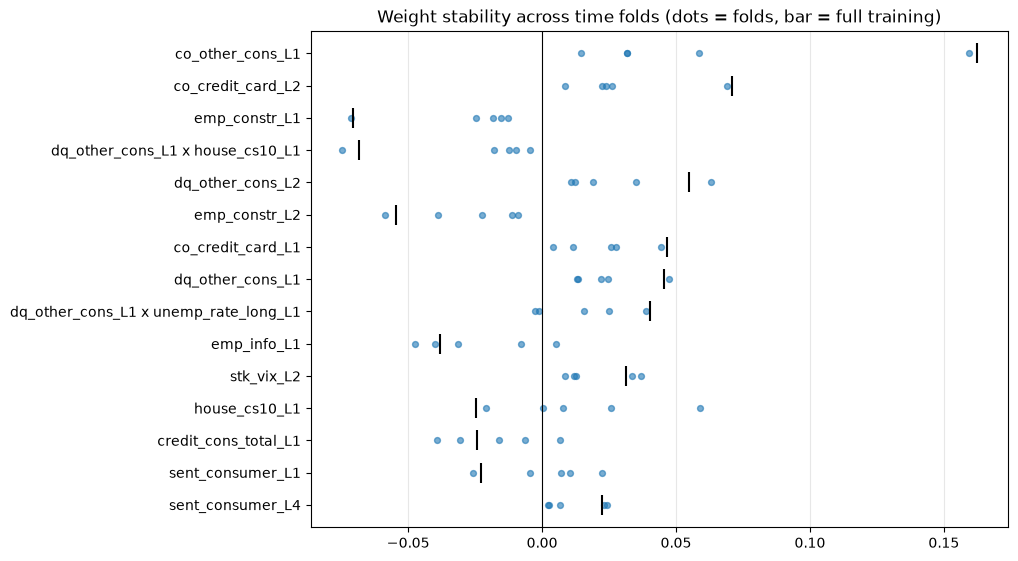

In [53]:
W_t, stab_t = weight_stability(target_best, X_train, y_train)
display(stab_t[stab_t.index.str.contains(r" x |\^2", regex=True)])   # are the added terms stable across folds?
plot_weight_stability(W_t, top=15)

<Axes: title={'center': 'Permutation importance (big train, small test = likely overfit)'}, xlabel='drop in root_mean_squared_error when shuffled'>

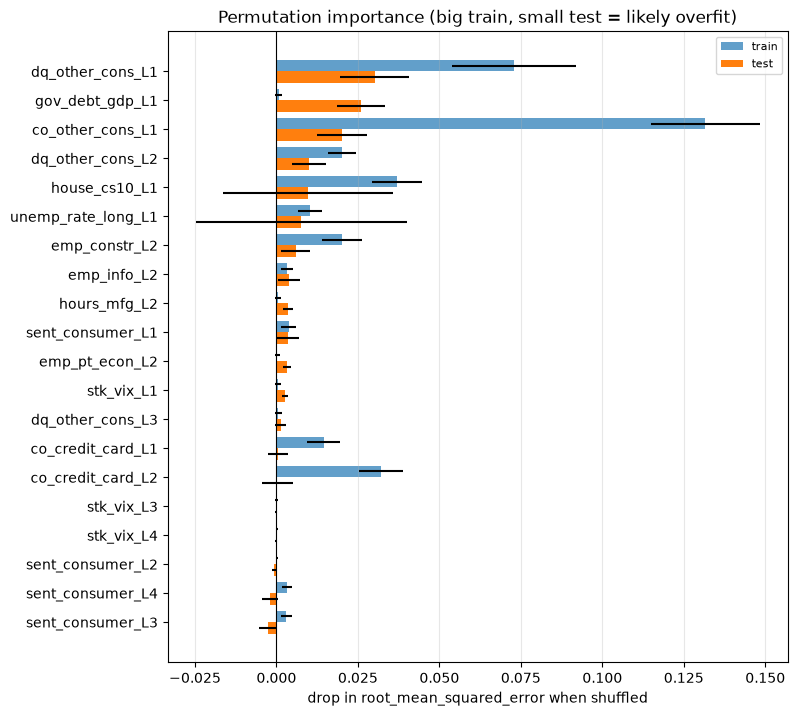

In [54]:
perm = permutation_table(target_best, X_train, y_train, X_test, y_test)
plot_permutation(perm)

In [55]:
record("Targeted terms + Ridge", target_best, X_train, X_test, y_train, y_test, search=target_search,
       notes=f"pairs={PAIRS}; squares={SQUARES}")

recorded 'Targeted terms + Ridge' -> /workspaces/DX799-O1/model_data/results


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.180,0.125,0.908,0.652,92.0
model - test,0.268,0.139,-0.109,0.614,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.099,0.081,0.779,0.667,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


### 5. Comparing A and B Models

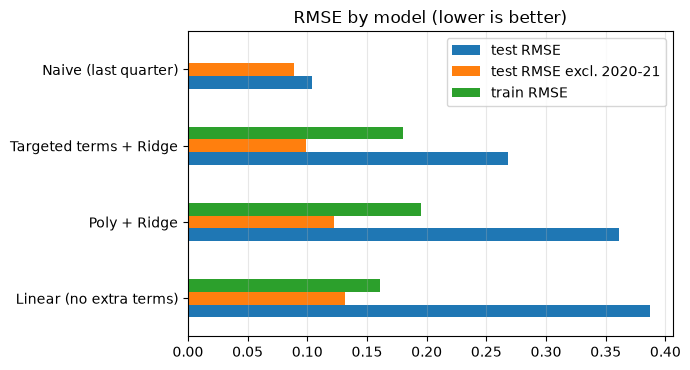

,type,test RMSE,test MAE,test R2,test DirAcc,test RMSE excl. 2020-21,train RMSE,overfit gap (test - train RMSE),CV score,CV metric,best params,saved
Naive (last quarter),baseline,0.104,0.066,0.832,NaN,0.089,NaN,NaN,NaN,NaN,NaN,NaN
Targeted terms + Ridge,regressor,0.268,0.139,-0.109,0.614,0.099,0.18,0.088,0.353107,root_mean_squared_error,"{'addterms__pairs': (('dq_other_cons_L1', 'une...",2026-10-18 01:43
Poly + Ridge,regressor,0.361,0.157,-1.014,0.636,0.122,0.195,0.166,0.38412,root_mean_squared_error,"{'polynomialfeatures__degree': 1, 'polynomialf...",2026-10-18 01:10
Linear (no extra terms),regressor,0.387,0.179,-1.307,0.591,0.132,0.161,0.226,None,None,None,2026-10-18 01:10


In [56]:
nb1 = ["Linear (no extra terms)", "Poly + Ridge", "Targeted terms + Ridge"]
compare(results={k: v for k, v in load_results().items() if k in nb1})

<Axes: title={'center': 'Test-period forecasts by model'}, ylabel='co_other_cons'>

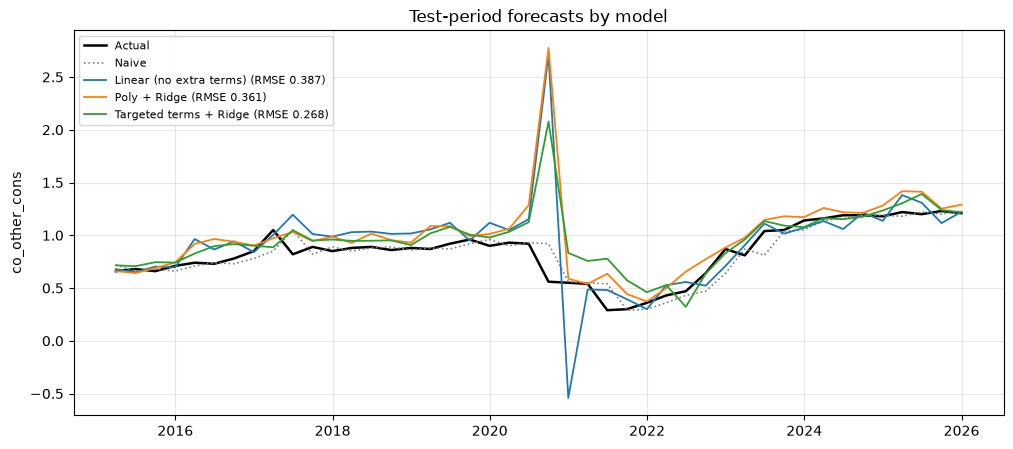

In [57]:
plot_forecasts(names=nb1)

### 6. Notes

- **Did extra terms help?** Compare test RMSE and DirAcc of the two approaches against the linear baseline and the naive forecast.
- **Which terms mattered?** Use the weight charts and the term-type table (share of weight on squares / interactions).
- **Overfitting:** train vs test RMSE gap; permutation importance on train vs test; stability of the added terms across folds.
- **Expected vs unexpected:** e.g. if `dq_other_cons_L1 × unemp_rate_L1` is positive and stable, that matches the idea that late loans roll into losses faster in weak labor markets.

## 7. Other - Misc

#### 1. Rerun Without Lagged Target Var

In [58]:
# b) Ablation: same model WITHOUT the lagged target -> how much do the macro features add on their own?
from sklearn.base import clone

class DropColumns(BaseEstimator, TransformerMixin):
    def __init__(self, cols=()):
        self.cols = cols
    def fit(self, X, y=None):
        self.keep_ = [c for c in X.columns if c not in self.cols]
        return self
    def transform(self, X):
        return X[self.keep_]
    def get_feature_names_out(self, input_features=None):
        return np.array(self.keep_)

target_lags = tuple(c for c in X_train.columns if c.startswith(meta["target"] + "_L"))
no_ar = make_pipeline(DropColumns(target_lags), *[step for _, step in clone(target_best).steps])
no_ar.fit(X_train, y_train)
score(no_ar, X_train, X_test, y_train, y_test)

,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.209,0.150,0.877,0.630,92.0
model - test,0.331,0.175,-0.696,0.614,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.118,0.098,0.688,0.667,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


#### 2. With Lagged Target Var (For Comparison)

In [59]:
score(target_best, X_train, X_test, y_train, y_test)

,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.180,0.125,0.908,0.652,92.0
model - test,0.268,0.139,-0.109,0.614,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.099,0.081,0.779,0.667,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0
